In [1]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'

# import os
# os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'

# This is required to run multiple processes with JAX.
from multiprocessing import set_start_method
set_start_method('forkserver', force=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
from tqdm import tqdm
from pathlib import Path

# print(jax.devices())
# jax.config.update("jax_debug_nans", True)

from train import Trainer
from config import Config
import data

In [3]:
cfg_path = Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/rgcn/era5.yml")
cfg = Config.from_file(cfg_path)
cfg.quiet = False
cfg.log = False

mgr = data.DynamicCacheManager(cfg)
cache_dir = mgr.create_cache('test')
dataset = data.CachedBasinGraphDataset(cfg, cache_dir, 'test')
cfg.num_workers = 0
dataloader = data.CachedBasinGraphDataLoader(cfg, dataset)

trainer = Trainer(cfg, dataloader)

Caches will be stored at: /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache4/c2d616fead0472c9
Indices for test already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for test...Done!
Dataloader using 0 parallel CPU worker(s).
Model contains 179,116 parameters


In [3]:
run_dir = Path("/nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled/era5_20260401_170510")
trainer = Trainer.load_from_run_or_state(run_dir)

trainer.cfg.quiet = False
mgr = data.DynamicCacheManager(trainer.cfg)
cache_dir = mgr.create_cache('test')
dataset = data.CachedBasinGraphDataset(trainer.cfg, cache_dir, 'test')

trainer.cfg.num_workers = 0
dataloader = data.CachedBasinGraphDataLoader(trainer.cfg, dataset)

Loading model from /nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled/era5_20260401_170510/checkpoints/step_050000
Model contains 401,420 parameters
Loading trainer from checkpoint step_050000
Logging at /nas/cee-water/cjgleason/ted/swot-ml/runs/sf_grnn_MS_pooled/era5_20260401_170510
Caches will be stored at: /scratch4/workspace/tlanghorst_umass_edu-zbs_vD/_cache4/6d9e60429fbee5c9
Indices for test already exist. Skipping.
Calculating training statistics for encoding and normalization...
Loading basin graphs...Done!
Loading optimized indices for test...Done!
Dataloader using 0 parallel CPU worker(s).


[1.6897759437561035,
 1.4731478691101074,
 1.5065521001815796,
 1.5024946928024292,
 1.3591240644454956,
 1.4744960069656372,
 1.4479161500930786,
 1.4140100479125977,
 1.4111425876617432,
 1.5247992277145386,
 1.3692083358764648,
 1.3130455017089844,
 1.5163655281066895,
 1.5045223236083984,
 1.4034812450408936,
 1.441619873046875,
 1.4986592531204224,
 1.4637558460235596,
 1.4905625581741333,
 1.5258151292800903,
 1.4525305032730103,
 1.5042176246643066,
 1.46739661693573,
 1.4809198379516602,
 1.4676640033721924,
 1.4652345180511475,
 1.5123178958892822,
 1.4178798198699951,
 1.4427752494812012,
 1.473218560218811,
 1.5269336700439453,
 1.4706103801727295,
 1.4358060359954834,
 1.333393931388855,
 1.399816632270813,
 1.5765169858932495,
 1.356955647468567,
 1.4695162773132324,
 1.5226378440856934,
 1.461290955543518,
 1.5076346397399902,
 1.3653678894042969,
 1.3866816759109497,
 1.3546754121780396,
 1.4354641437530518,
 1.6332995891571045,
 1.511298418045044,
 1.5662705898284912,
 

In [4]:
for basins, subbasins, dates, batch in tqdm(dataloader):
    break


  0%|          | 0/1000000000000 [00:04<?, ?it/s]


In [21]:
import equinox as eqx

model = eqx.tree_at(lambda m: m.return_weights, trainer.model, True)

In [22]:
key = jax.random.PRNGKey(0)
y_hat, weights = model(batch, key)

In [7]:
np.where(~np.isnan(batch.dynamic['swot-river'][:,0,0]))

(array([ 1,  7, 18, 22, 28, 39, 42, 49, 60, 70, 81, 84]),)

In [23]:
np.where(~np.isnan(weights['assim']['swot-river']['gain'][:,0,0]))

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50,
        51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
        68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84,
        85, 86, 87, 88, 89]),)

In [24]:
batch.dynamic['swot-river'][1,0,:]

array([ 0.22533948, -0.60188494, -0.66352318, -0.0919452 , -0.27088198,
       -0.2708306 ,  0.61782255, -0.00305678, -0.46487624, -0.0030569 ,
        0.7134755 ,  1.        ,  0.        ,  0.        ,  1.        ,
        1.        ,  0.        ])

In [27]:
weights['assim']['swot-river']['gain'][1,0,:]

Array([ 0.06846132, -0.03998389,  0.06961817, -0.02028389, -0.00828576,
       -0.00762198,  0.0130658 ,  0.09379461, -0.0148216 , -0.07455137,
       -0.13800555,  0.00027183,  0.06666683,  0.07176693,  0.11048311,
        0.03494554, -0.05783743,  0.00349437, -0.15661995,  0.03736218,
       -0.06472966,  0.10506549, -0.07261571,  0.0026831 ,  0.03073703,
        0.00715699,  0.085599  ,  0.01934697, -0.23188491, -0.06148471,
        0.07988431, -0.00148997,  0.04747592,  0.00624236, -0.11424184,
        0.04735611,  0.0286572 ,  0.00359678,  0.00243788, -0.04247313,
       -0.01171039, -0.11679661, -0.12230119, -0.16049322, -0.01605568,
       -0.04105455, -0.10160735,  0.01561199,  0.03234623, -0.01625723,
        0.02585673, -0.0906352 ,  0.01402064, -0.04858983, -0.06523948,
        0.05709246,  0.05594014, -0.0793568 , -0.1863137 , -0.0294601 ,
       -0.03508851, -0.03078129,  0.03434196,  0.0298308 ], dtype=float32)

In [65]:
# params, _ = 
opt_state = optimizer.init(eqx.filter(model, eqx.is_inexact_array))

In [ ]:
opt_state

In [41]:
getattr(model,'sparse_embedders')

{'swot-river': StaticMLP(
   append_static=True,
   mlp=MLP(
     layers=(
       Linear(
         weight=f32[96,81],
         bias=f32[96],
         in_features=81,
         out_features=96,
         use_bias=True
       ),
       Linear(
         weight=f32[96,96],
         bias=f32[96],
         in_features=96,
         out_features=96,
         use_bias=True
       ),
       Linear(
         weight=f32[64,96],
         bias=f32[64],
         in_features=96,
         out_features=64,
         use_bias=True
       )
     ),
     activation=<PjitFunction of <function relu at 0x771ae40696c0>>,
     final_activation=<function <lambda>>,
     use_bias=True,
     use_final_bias=True,
     in_size=81,
     out_size=64,
     width_size=96,
     depth=2
   )
 )}

In [39]:
model.sparse_embedders

{'swot-river': StaticMLP(
   append_static=True,
   mlp=MLP(
     layers=(
       Linear(
         weight=f32[96,81],
         bias=f32[96],
         in_features=81,
         out_features=96,
         use_bias=True
       ),
       Linear(
         weight=f32[96,96],
         bias=f32[96],
         in_features=96,
         out_features=96,
         use_bias=True
       ),
       Linear(
         weight=f32[64,96],
         bias=f32[64],
         in_features=96,
         out_features=64,
         use_bias=True
       )
     ),
     activation=<PjitFunction of <function relu at 0x771ae40696c0>>,
     final_activation=<function <lambda>>,
     use_bias=True,
     use_final_bias=True,
     in_size=81,
     out_size=64,
     width_size=96,
     depth=2
   )
 )}

In [13]:
weights['fusion']['weights'].shape

(90, 32580, 2)

In [17]:
y_true = batch.y['discharge'][0,...,0]
node_mask = batch.node_mask

valid_mask = (~np.isnan(y_true)) & node_mask
masked_y = np.where(valid_mask, y_true, 0)
expanded_mask = np.expand_dims(valid_mask, axis=-1)

expanded_mask.shape

(32580, 1)

In [18]:
np.sum(valid_mask)

1552

In [19]:
y_hat_target = y_hat['discharge']
masked_y_hat = {
    "mu": jnp.where(expanded_mask, y_hat_target["mu"], 0.0),
    "sigma": jnp.where(expanded_mask, y_hat_target["sigma"], 1.0),  # sigma=1 is safe
    "log_pi": jnp.where(expanded_mask, y_hat_target["log_pi"], 1.0 / y_hat_target["log_pi"].shape[-1]),  # uniform is safe
}

In [20]:
y_obs = jnp.expand_dims(masked_y, axis=-1)  # Allow broadcasting to each error model
mu = masked_y_hat["mu"]
sigma = masked_y_hat["sigma"]
log_pi = masked_y_hat["log_pi"]

# 1. log(pdf) = -log(sigma) - 0.5*log(2*pi) - 0.5 * ((y-mu)/sigma)^2
log_sigma = jnp.log(sigma)
log_2pi = jnp.log(2.0 * jnp.pi)

# Calculate Mahalanobis distance with clipping
# Gradient of sq_diff w.r.t sigma is proportional to 1/sigma^3. 
# Clipping here is the 'safety valve' for your grad norm.
scaled_diff = (y_obs - mu) / sigma
sq_diff = jnp.square(jnp.clip(scaled_diff, -10.0, 10.0))

log_phi = -log_sigma - 0.5 * log_2pi - 0.5 * sq_diff

# 2. log(sum(pi * pdf)) = logsumexp(log_pi + log_phi)
# Both terms are already in log-space.
log_likelihood = jax.scipy.special.logsumexp(log_pi + log_phi, axis=-1)

# 3. Masked Mean
# Note: sum(mask) + 1e-8 prevents div-by-zero on empty batches
-jnp.sum(log_likelihood * valid_mask) / (jnp.sum(valid_mask) + 1e-8)

Array(0.7061219, dtype=float32)

In [24]:
log_pi[valid_mask]

Array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)

In [14]:
np.mean(log_weighted_likelihoods, where=valid_mask)

Array(-1.1708583, dtype=float32)

In [103]:
valid_mask.shape

(8200,)

In [120]:
y_hat_target['sigma'].shape

(8200, 100)

In [107]:
y_hat['sigma'][valid_mask]

Array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)

In [81]:
masked_y_hat['sigma'][valid_mask[0,...], :]

Array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)

In [65]:
node_mask[jnp.newaxis,:].shape

(1, 8200)

In [18]:
log_pi

Array([[[-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        ...,
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702],
        [-4.6051702, -4.6051702, -4.6051702, ..., -4.6051702,
         -4.6051702, -4.6051702]]], dtype=float32)

In [17]:
-jnp.mean(log_weighted_likelihoods, where=valid_mask)

Array(nan, dtype=float32)

In [160]:
valid_mask.shape

(1, 8200)

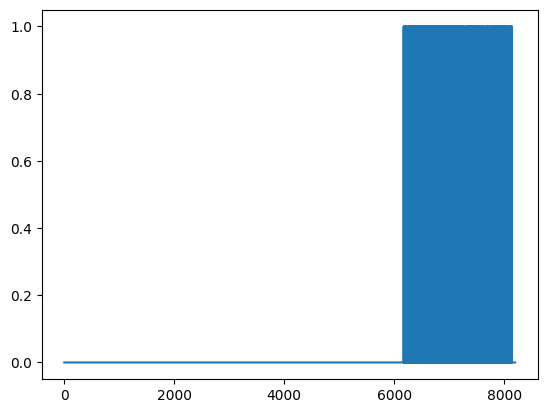

In [141]:
plt.plot(jnp.isnan(log_weighted_likelihoods).T)

In [137]:
valid_mask.shape

(1, 8200)

In [136]:
log_weighted_likelihoods.shape

(1, 8200)

In [131]:
import train

train.loss.gmm_nll(masked_y, masked_y_hat, valid_mask, None)

Array(nan, dtype=float32)

In [114]:
np.nansum(batch.y['discharge'][0,:,0])

88.6320204432597

In [ ]:
obs_emb['swot-river'][0].shape

In [ ]:
batch.dynamic['swot-river'].shape

In [ ]:
sub_m

In [ ]:
batch.dynamic['swot-river'][:, batch.node_mask, :]

In [ ]:
batch.node_mask[None,:,None].shape